# T20. Primera matriz origen-destino en H3

**Objetivo.** Construir la matriz origen-destino de los viajes entre celdas H3 de resolución 8 y describir sus pares principales, la parte intrazonal y su asimetría.

**Valor para el proyecto.** Es la primera matriz O-D del requisito de movilidad. Dice cuántos viajes no salen de su zona, si la demanda se concentra en pocos corredores y si los flujos son simétricos o hay corredores que vacían una zona hacia otra.

Viajes elegibles del periodo de ajuste (1–21/02), agregados por la celda del origen y la del destino.

In [1]:
import h3
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap, LogNorm
from matplotlib.ticker import FuncFormatter
from scipy.stats import binom

from comun.config import cargar_config, carpeta_tablas
from comun.datos import cargar_viajes
from comun.figuras import guardar_figura, plt
from comun.web import exportar

TEMA, FASE = "movilidad", "fase1"
TABLAS = carpeta_tablas(TEMA)
CFG = cargar_config()

PARAMETROS = {
    "res": CFG["movilidad"]["resolucion_mapas"],
    "celdas_mapa_calor": 30,
    "pares_top": 20,
    "pares_asimetria_top": 10,
}
TITULO_AJUSTE = "viajes elegibles del periodo de ajuste (1–21/02/2021)"
CMAP_SECUENCIAL = LinearSegmentedColormap.from_list(
    "azules", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
CMAP_SECUENCIAL.set_bad("#f0efec")


def guardar_tabla(df, nombre):
    df.to_csv(TABLAS / f"{nombre}.csv", index=False, lineterminator="\n")


def tabla_resumen(resumen):
    valores = [round(float(x), 4) if isinstance(x, (float, np.floating)) else int(x) for x in resumen.values()]
    return pd.DataFrame({"indicador": list(resumen), "valor": pd.Series(valores, dtype=object)})


def celda(lat, lon, res):
    return pd.Series([h3.latlng_to_cell(a, b, res) for a, b in zip(lat, lon)], index=lat.index, dtype="string")


viajes = cargar_viajes(periodo="ajuste")
RES = PARAMETROS["res"]
print(f"{len(viajes)} viajes elegibles en el periodo de ajuste")

16756 viajes elegibles en el periodo de ajuste


## 1. Matriz larga

**Qué queremos ver.** La tabla `h3_o`, `h3_d`, `viajes` con todos los pares con viajes, y cuántas celdas y pares hay.

**Por qué importa.** Es la base de las matrices por franja y tipo de día y de la asignación a estaciones de la fase 1.

In [2]:
od = pd.DataFrame({"h3_o": celda(viajes["latO"], viajes["lonO"], RES),
                   "h3_d": celda(viajes["latD"], viajes["lonD"], RES)})
od = od.groupby(["h3_o", "h3_d"]).size().rename("viajes").reset_index()
od = od.sort_values(["viajes", "h3_o", "h3_d"], ascending=[False, True, True], ignore_index=True)
assert od["viajes"].sum() == len(viajes)
guardar_tabla(od, f"T20_od_res{RES}")

# Celdas ordenadas por orígenes + destinos, con su rango y su centro.
orig = od.groupby("h3_o")["viajes"].sum().rename("origenes")
dest = od.groupby("h3_d")["viajes"].sum().rename("destinos")
celdas = pd.concat([orig, dest], axis=1).fillna(0).astype("int64")
celdas.index.name = "h3"
celdas["extremos"] = celdas["origenes"] + celdas["destinos"]
celdas = celdas.reset_index().sort_values(["extremos", "h3"], ascending=[False, True], ignore_index=True)
celdas.insert(0, "rango", np.arange(1, len(celdas) + 1))
centro = np.array([h3.cell_to_latlng(c) for c in celdas["h3"]])
celdas["lat"], celdas["lon"] = centro[:, 0].round(6), centro[:, 1].round(6)

intra = od["h3_o"] == od["h3_d"]
indicadores = {
    "res": RES,
    "viajes": len(viajes),
    "celdas_origen": int(od["h3_o"].nunique()),
    "celdas_destino": int(od["h3_d"].nunique()),
    "pares_con_viajes": len(od),
    "pares_posibles": int(od["h3_o"].nunique() * od["h3_d"].nunique()),
    "viajes_intrazonales": int(od.loc[intra, "viajes"].sum()),
    "pct_viajes_intrazonales": 100 * od.loc[intra, "viajes"].sum() / len(viajes),
    "pct_viajes_top20_pares": 100 * od.head(PARAMETROS["pares_top"])["viajes"].sum() / len(viajes),
}
display(pd.Series(indicadores).to_frame("valor"))

,valor
res,8.000000
viajes,16756.000000
celdas_origen,103.000000
celdas_destino,111.000000
pares_con_viajes,2157.000000
pares_posibles,11433.000000
viajes_intrazonales,3588.000000
pct_viajes_intrazonales,21.413225
pct_viajes_top20_pares,14.770828


**Conclusiones.**

- Los viajes salen de 103 celdas y llegan a 111. Hay 2 157 pares con viajes de los 11 433 posibles.
- El **21,4 %** de los viajes empieza y acaba en la misma celda de resolución 8.

## 2. Mapa de calor de las 30 celdas con más extremos

**Qué queremos ver.** La matriz entre las 30 celdas con más orígenes + destinos, con el mismo orden en filas y columnas.

**Por qué importa.** Muestra de un vistazo si los viajes se quedan en la diagonal (viajes cortos dentro de la zona) o conectan zonas alejadas.

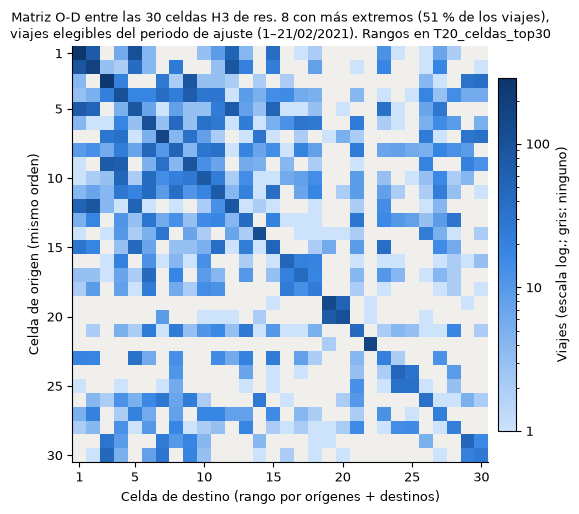

In [3]:
n = PARAMETROS["celdas_mapa_calor"]
top = celdas.head(n)
guardar_tabla(top, f"T20_celdas_top{n}")
m = (od[od["h3_o"].isin(top["h3"]) & od["h3_d"].isin(top["h3"])]
     .pivot(index="h3_o", columns="h3_d", values="viajes")
     .reindex(index=top["h3"], columns=top["h3"]))
valores = m.to_numpy(dtype=float)
pct_top = 100 * np.nansum(valores) / od["viajes"].sum()
indicadores[f"pct_viajes_entre_top{n}_celdas"] = pct_top

fig, eje = plt.subplots(figsize=(6.5, 5.4))
im = eje.imshow(np.ma.masked_invalid(valores), cmap=CMAP_SECUENCIAL, norm=LogNorm(vmin=1, vmax=np.nanmax(valores)),
                interpolation="nearest")
marcas = [0] + list(range(4, n, 5))
eje.set_xticks(marcas)
eje.set_yticks(marcas)
eje.set_xticklabels([str(i + 1) for i in marcas])
eje.set_yticklabels([str(i + 1) for i in marcas])
eje.grid(False)
eje.set_xlabel("Celda de destino (rango por orígenes + destinos)")
eje.set_ylabel("Celda de origen (mismo orden)")
barra = fig.colorbar(im, ax=eje, shrink=0.85, pad=0.02)
barra.ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
barra.set_label("Viajes (escala log.; gris: ninguno)")
eje.set_title(f"Matriz O-D entre las {n} celdas H3 de res. {RES} con más extremos ({pct_top:.0f} % de los viajes),\n"
              f"{TITULO_AJUSTE}. Rangos en T20_celdas_top{n}", fontsize=9)
guardar_figura(fig, TEMA, f"T20_od_top{n}")

exportar(FASE, "t20_od_top30", {"celdas": top, "viajes": np.nan_to_num(valores).astype(int),
                                "pct_viajes": pct_top})

**Conclusiones.**

- Las 30 celdas con más extremos reúnen el 51,0 % de los viajes entre ellas.
- La diagonal es la parte más oscura: los viajes más frecuentes son los que se quedan en su celda o van a una vecina.

## 3. Pares con más viajes

**Qué queremos ver.** Los 20 pares con más viajes, con y sin los intrazonales.

**Por qué importa.** Indica los corredores principales que la red de estaciones debe servir bien.

In [4]:
rango = celdas.set_index("h3")["rango"]
for sufijo, sub in [("", od), ("_entre_celdas", od[~intra])]:
    pares = sub.head(PARAMETROS["pares_top"]).copy()
    pares["intrazonal"] = pares["h3_o"] == pares["h3_d"]
    pares["rango_o"] = pares["h3_o"].map(rango)
    pares["rango_d"] = pares["h3_d"].map(rango)
    pares["pct_viajes"] = (100 * pares["viajes"] / len(viajes)).round(2)
    # Distancia en celdas H3 (0: misma celda; 1: vecinas).
    pares["distancia_h3"] = [h3.grid_distance(a, b) for a, b in zip(pares["h3_o"], pares["h3_d"])]
    guardar_tabla(pares, f"T20_pares_top{PARAMETROS['pares_top']}{sufijo}")
    exportar(FASE, f"t20_pares_top{PARAMETROS['pares_top']}{sufijo}", pares)
    display(pares.head(8))

,h3_o,h3_d,viajes,intrazonal,rango_o,rango_d,pct_viajes,distancia_h3
0,881e805089fffff,881e805089fffff,289,True,1,1,1.72,0
1,881e805003fffff,881e805003fffff,251,True,3,3,1.50,0
2,881e8050c3fffff,881e8050c3fffff,185,True,2,2,1.10,0
3,881e805189fffff,881e805189fffff,160,True,22,22,0.95,0
4,881e805015fffff,881e805015fffff,156,True,7,7,0.93,0
5,881e8051d1fffff,881e8051d1fffff,135,True,19,19,0.81,0
6,881e805017fffff,881e805017fffff,120,True,14,14,0.72,0
7,881e8051dbfffff,881e8051dbfffff,106,True,20,20,0.63,0


,h3_o,h3_d,viajes,intrazonal,rango_o,rango_d,pct_viajes,distancia_h3
8,881e805089fffff,881e8050c1fffff,105,False,1,5,0.63,2
11,881e8050c3fffff,881e805089fffff,91,False,2,1,0.54,1
13,881e8050c3fffff,881e8050c7fffff,88,False,2,12,0.53,1
14,881e8050c7fffff,881e8050c3fffff,86,False,12,2,0.51,1
15,881e805003fffff,881e80501dfffff,85,False,3,9,0.51,1
19,881e805089fffff,881e8050d5fffff,77,False,1,35,0.46,1
20,881e80501dfffff,881e805003fffff,74,False,9,3,0.44,1
21,881e8050c1fffff,881e805089fffff,74,False,5,1,0.44,2


**Conclusiones.**

- Los 20 pares con más viajes reúnen el 14,8 % de los viajes: la demanda no se concentra en pocos corredores.
- De los 20 pares principales entre celdas distintas, 18 unen celdas vecinas (`distancia_h3` = 1) y los otros 2 están a dos celdas. Los mismos pares aparecen en los dos sentidos con volúmenes parecidos.

## 4. Asimetría M − Mᵀ

**Qué queremos ver.** Cuánto se diferencian los dos sentidos de cada par de celdas distintas, comparado con lo que daría el azar si los dos sentidos fueran igual de probables.

**Por qué importa.** Si unos pocos corredores fueran muy asimétricos, el rebalanceo podría plantearse por corredores; si no, hay que plantearlo por zonas (T14).

In [5]:
# Para un par {i, j} con n viajes en total, si los dos sentidos fueran igual de probables
# |M_ij − M_ji| tendría la media de |2X − n| con X ~ Bin(n, 1/2).
inter = od[~intra]
a = inter.rename(columns={"viajes": "ij"})
b = inter.rename(columns={"h3_o": "h3_d", "h3_d": "h3_o", "viajes": "ji"})
pares = a.merge(b, on=["h3_o", "h3_d"], how="outer").fillna({"ij": 0, "ji": 0})
pares = pares[pares["h3_o"] < pares["h3_d"]].copy()
pares[["ij", "ji"]] = pares[["ij", "ji"]].astype("int64")
pares["total"] = pares["ij"] + pares["ji"]
pares["neto_ij_menos_ji"] = pares["ij"] - pares["ji"]
pares["abs_neto"] = pares["neto_ij_menos_ji"].abs()

esperado = 0.0
for n_par, veces in pares["total"].value_counts().items():
    k = np.arange(n_par + 1)
    esperado += veces * float(np.sum(np.abs(2 * k - n_par) * binom.pmf(k, n_par, 0.5)))

asim_top = (pares.sort_values(["abs_neto", "total", "h3_o", "h3_d"], ascending=[False, False, True, True])
            .head(PARAMETROS["pares_asimetria_top"]))
asim_top = asim_top.assign(rango_o=asim_top["h3_o"].map(rango), rango_d=asim_top["h3_d"].map(rango))
asim_top = asim_top[["h3_o", "h3_d", "rango_o", "rango_d", "ij", "ji", "total", "neto_ij_menos_ji"]]
guardar_tabla(asim_top, f"T20_asimetria_pares_top{PARAMETROS['pares_asimetria_top']}")

# Comprobación: la suma por filas de M − Mᵀ es el saldo orígenes − destinos de cada celda.
neto = od.groupby("h3_o")["viajes"].sum().sub(od.groupby("h3_d")["viajes"].sum(), fill_value=0)
saldo_celda = celdas.set_index("h3")["origenes"] - celdas.set_index("h3")["destinos"]
assert (neto.reindex(saldo_celda.index) == saldo_celda).all()

viajes_inter = int(pares["total"].sum())
indicadores.update({
    "pares_entre_celdas_con_viajes": len(pares),
    "suma_abs_asimetria_pares": int(pares["abs_neto"].sum()),
    "indice_asimetria": pares["abs_neto"].sum() / viajes_inter,
    "indice_asimetria_esperado_azar": esperado / viajes_inter,
    "cociente_asimetria_observada_esperada": pares["abs_neto"].sum() / esperado,
    "max_abs_asimetria_par": int(pares["abs_neto"].max()),
})
exportar(FASE, "t20_asimetria", {"pares_top": asim_top,
                                 "indice": indicadores["indice_asimetria"],
                                 "indice_azar": indicadores["indice_asimetria_esperado_azar"]})
display(asim_top)

,h3_o,h3_d,rango_o,rango_d,ij,ji,total,neto_ij_menos_ji
832,881e805089fffff,881e8050c1fffff,1,5,105,74,179,31
830,881e805089fffff,881e80508bfffff,1,53,51,23,74,28
962,881e8050c3fffff,881e8050ddfffff,2,48,48,27,75,21
1450,881e8051d1fffff,881e8051dbfffff,19,20,54,74,128,-20
279,881e805019fffff,881e805053fffff,4,10,28,48,76,-20
839,881e805089fffff,881e8050d5fffff,1,35,77,58,135,19
833,881e805089fffff,881e8050c3fffff,1,2,73,91,164,-18
0,881e805001fffff,881e805003fffff,68,3,13,31,44,-18
915,881e8050c1fffff,881e8050c7fffff,5,12,72,56,128,16
831,881e805089fffff,881e80508dfffff,1,55,52,36,88,16


**Conclusiones.**

- La suma de |M − Mᵀ| es el 22,3 % de los viajes entre celdas distintas, frente al 20,4 % que daría el azar: **solo 1,09 veces lo esperable**. El par más asimétrico tiene 31 viajes de diferencia.
- El saldo de las zonas (T14) es la suma de muchos pares pequeños, no de unos pocos corredores: el rebalanceo se plantea por zonas.

## 5. Tabla de indicadores

**Qué queremos ver.** Todos los indicadores de la matriz en una tabla.

**Por qué importa.** Es la tabla que citan `docs/conclusiones_eda.md` y la memoria.

In [6]:
resumen = tabla_resumen(indicadores)
guardar_tabla(resumen, "T20_resumen")
exportar(FASE, "t20_resumen", resumen)
display(resumen)

,indicador,valor
0,res,8
1,viajes,16756
2,celdas_origen,103
3,celdas_destino,111
4,pares_con_viajes,2157
5,pares_posibles,11433
6,viajes_intrazonales,3588
7,pct_viajes_intrazonales,21.4132
8,pct_viajes_top20_pares,14.7708
9,pct_viajes_entre_top30_celdas,50.9847


## Decisiones

| Decisión | Valor |
|---|---|
| Viajes intrazonales en resolución 8 | 21,4 %; con radios de 300 m o más, parte empezarían y acabarían en la misma estación |
| Corredores asimétricos | No hay: los pares son casi simétricos y el rebalanceo se plantea por zonas |

El detalle de cada decisión está en `docs/conclusiones_eda.md`.